# Human pseudotime already on the object — violins and spatial plots

**Loads, does not compute.** Reads `dpt_pseudotime` as it currently stands on the netscratch human fib/dec
object and plots it raw and quantile-normalised. CPU only, a couple of minutes. Companion to
`loaded_pseudotime_mouse.ipynb`.

**Object:** `/n/netscratch/eddy_lab/Everyone/nhilgert/2026_08_28_Cevrim_Human_Only_Fib_Dec_Cells.h5ad`
(47,533 cells; `x_um_qc`/`y_um_qc`/`tissue_section` from the 2026-09-02 QC sync — human is **degenerate-only**
by decision, so only 3 cells are excluded).

**Provenance of the loaded pseudotime** — the human object records it explicitly in
`obs['dpt_pseudotime_provenance']`, printed in full by §1: moscot TemporalProblem → CellRank RealTimeKernel →
DPT, run 2026-08-29 on the 04b stromal scVI latent, root = earliest phase (secretory). Two things that string
says and §3 re-measures rather than trusts:

- **only 1 moscot transition** exists in human (secretory → menstrual) versus 5 in mouse, and there is no fine
  subtype anchor — human has just `endometrial_fibroblast` and `decidual_cell`;
- the recorded `Spearman(pt, day) = +0.313`, flagged in the string itself as *modest* — "do not interpret as
  strongly time-ordered". §3 recomputes it from the values on disk.

**Quantile normalisation.** `dpt_q` = each cell's percentile among cells with a value (`rank(pct=True)`):
identical ordering (asserted in §2), uniform spacing. `dpt_qsec` normalises within tissue section — for
comparing trajectory *shape* between sections only, never to claim one section is further along.

**Violin fill = the category's median**, on the same colour scale the spatial panels use for that column, so a
violin's colour is the colour the tissue takes at that category's typical position.

Nothing here writes to the object.

In [1]:
import pathlib, json, h5py, warnings
import numpy as np, pandas as pd, scanpy as sc
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from scipy.stats import spearmanr
warnings.filterwarnings("ignore")
try:    from anndata.io import read_elem
except ImportError: from anndata.experimental import read_elem

N   = pathlib.Path("/n/netscratch/eddy_lab/Everyone/nhilgert")
SRC = N/"2026_08_28_Cevrim_Human_Only_Fib_Dec_Cells.h5ad"
OUT = pathlib.Path("/n/lab_storage/eddy_lab/users/nhilgert/xmens_final/results/pseudotime_loaded_human")
SUBCL = pathlib.Path("/n/lab_storage/eddy_lab/users/nhilgert/xmens_final/results/human_dec_subclusters.csv")  # optional finer decidual labels
OUT.mkdir(parents=True, exist_ok=True)
PTCOL = "dpt_pseudotime"

# human: two subtypes, two phases; biological order secretory (decidualizing) -> menstrual (shedding)
SUBORDER = ["endometrial_fibroblast", "decidual_cell"]
TPORDER  = ["secretory", "menstrual"]
RANK, TPRANK = {s:i for i,s in enumerate(SUBORDER)}, {t:i for i,t in enumerate(TPORDER)}
PAL  = dict(zip(SUBORDER, sns.color_palette("viridis", len(SUBORDER))))
TPAL = dict(zip(TPORDER,  sns.color_palette("rocket_r", len(TPORDER))))

CHECKS = []
def verify(label, got, note=""):
    ok = bool(got); CHECKS.append((label, ok, str(got), note))
    print(("PASS  " if ok else "FAIL  ") + label + f"   [{got}]" + (f"  {note}" if note else "")); return ok
print("source:", SRC, "| exists:", SRC.exists())

source: /n/netscratch/eddy_lab/Everyone/nhilgert/2026_08_28_Cevrim_Human_Only_Fib_Dec_Cells.h5ad | exists: True


## 1 — load obs only and print the provenance

In [2]:
WANT = [PTCOL, "cell_subtype", "cell_type", "timepoint", "sample",
        "x_um_qc", "y_um_qc", "tissue_section", "spatial_qc_reason"]
with h5py.File(SRC, "r") as f:
    have = [c for c in WANT if c in f["obs"].keys()]
    missing = [c for c in WANT if c not in have]
    res = pd.DataFrame({c: np.asarray(read_elem(f[f"obs/{c}"])).ravel() for c in have},
                       index=pd.Index(np.asarray(read_elem(f["obs/_index"])).ravel(), name="cell"))
    prov_cols = [c for c in f["obs"].keys() if "provenance" in c or "root" in c]
    prov = {c: str(np.asarray(read_elem(f[f"obs/{c}"])).ravel()[0]) for c in prov_cols}
    uns_pt = {k: read_elem(f[f"uns/{k}"]) for k in f["uns"].keys() if "pseudo" in k.lower() or "dpt" in k.lower()}
print("loaded obs:", res.shape, "| missing:", missing)
for c in ("cell_subtype","cell_type","timepoint","sample","tissue_section","spatial_qc_reason"):
    if c in res: res[c] = res[c].astype(str)
res[PTCOL] = pd.to_numeric(res[PTCOL], errors="coerce")
for c in ("x_um_qc","y_um_qc"): res[c] = pd.to_numeric(res[c], errors="coerce")

print("\n=== provenance recorded on the object ===")
for k, v in prov.items(): print(f"\nobs['{k}']:\n  {v[:900]}")
for k, v in uns_pt.items(): print(f"\nuns['{k}']: {json.dumps(v, default=str)[:600]}")
if not prov and not uns_pt: print("  (no provenance string found on this object)")

verify(f"{PTCOL} present", PTCOL in res.columns)
verify("QC'd coordinates + tissue_section present", {"x_um_qc","y_um_qc","tissue_section"} <= set(res.columns))
print(f"\ncoverage: {int(res[PTCOL].notna().sum()):,} of {len(res):,} cells have a pseudotime value")
print(f"range: min {res[PTCOL].min():.4g}  median {res[PTCOL].median():.4g}  max {res[PTCOL].max():.4g}")
print("\nfinite pseudotime by timepoint:"); display(pd.crosstab(res.timepoint, res[PTCOL].notna()).reindex(TPORDER))
print("subtype x phase:"); display(pd.crosstab(res.cell_subtype, res.timepoint).reindex(index=SUBORDER, columns=TPORDER))
print("finite pseudotime by subtype:");    display(pd.crosstab(res.cell_subtype, res[PTCOL].notna()).reindex([s for s in SUBORDER if s in set(res.cell_subtype)]))

loaded obs: (47533, 9) | missing: []

=== provenance recorded on the object ===

obs['dpt_pseudotime_provenance']:
  human_pseudotime.ipynb v1_all_cells 2026-08-29; moscot TemporalProblem -> CellRank RealTimeKernel -> DPT; scVI = 04b latent_human_stromal; UMAP computed on the 47,533 fib/dec cells; root = earliest timepoint (secretory), no fine subtype anchor exists in human; 1 moscot transition only. Spearman(pt,day) = +0.313 — a MODEST effect: do not interpret as strongly time-ordered (mouse, with 5 transitions and an efib_proliferative anchor, gives +0.665).
PASS  dpt_pseudotime present   [True]
PASS  QC'd coordinates + tissue_section present   [True]

coverage: 47,533 of 47,533 cells have a pseudotime value
range: min 0  median 0.408  max 1

finite pseudotime by timepoint:


dpt_pseudotime,True
timepoint,
secretory,23441
menstrual,24092


subtype x phase:


timepoint,secretory,menstrual
cell_subtype,,
endometrial_fibroblast,17891,7994
decidual_cell,5550,16098


finite pseudotime by subtype:


dpt_pseudotime,True
cell_subtype,
endometrial_fibroblast,25885
decidual_cell,21648


### optional: finer decidual labels

Two subtypes make thin violins. If the decidual subclustering table is present, join `leiden_0.3` (4 clusters, the resolution the sweep selected) as `dec_subcluster` for the extra violin panel in §4. This is display only — it does not touch the pseudotime.

In [3]:
if SUBCL.exists():
    sub = pd.read_csv(SUBCL, index_col=0)
    col = "leiden_0.3"
    assert col in sub.columns, f"{col} not in {list(sub.columns)}"
    lab = sub[col].reindex(res.index)
    res["dec_subcluster"] = np.where(res.cell_subtype == "decidual_cell",
                                     "dec_" + lab.astype("Int64").astype(str), res.cell_subtype)
    print("joined decidual subclusters:", res.dec_subcluster.value_counts().to_dict())
    verify("every decidual cell got a subcluster label",
           not res.loc[res.cell_subtype == "decidual_cell", "dec_subcluster"].str.contains("<NA>").any())
else:
    res["dec_subcluster"] = res.cell_subtype
    print("no subcluster file at", SUBCL, "— violins use cell_subtype only")

joined decidual subclusters: {'endometrial_fibroblast': 25885, 'dec_0': 15076, 'dec_1': 4678, 'dec_2': 1054, 'dec_3': 840}
PASS  every decidual cell got a subcluster label   [True]


## 2 — quantile normalise

PASS  quantile transform preserves the ordering exactly   [True]
median by subtype:


,raw,quantile
cell_subtype,,
endometrial_fibroblast,0.398,0.295
decidual_cell,0.427,0.760


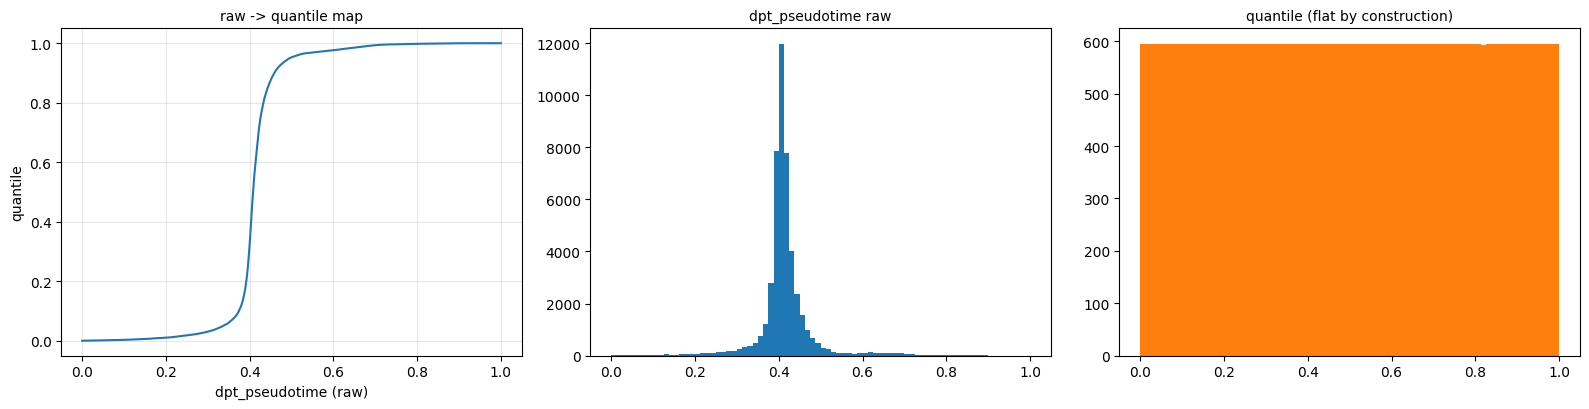

In [4]:
res["dpt_q"]    = res[PTCOL].rank(pct=True)
res["dpt_qsec"] = res.groupby("tissue_section", observed=True)[PTCOL].rank(pct=True)
m = res[PTCOL].notna()
verify("quantile transform preserves the ordering exactly",
       float(spearmanr(res.loc[m, PTCOL], res.loc[m, "dpt_q"]).statistic) == 1.0)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
v = np.sort(res.loc[m, PTCOL].to_numpy())
axes[0].plot(v, np.linspace(0, 1, len(v)), lw=1.5); axes[0].grid(alpha=.3)
axes[0].set_xlabel(f"{PTCOL} (raw)"); axes[0].set_ylabel("quantile"); axes[0].set_title("raw -> quantile map", fontsize=10)
axes[1].hist(res.loc[m, PTCOL], bins=80, color="C0"); axes[1].set_title(f"{PTCOL} raw", fontsize=10)
axes[2].hist(res.loc[m, "dpt_q"], bins=80, color="C1"); axes[2].set_title("quantile (flat by construction)", fontsize=10)
fig.tight_layout()

print("median by subtype:")
display(pd.DataFrame({"raw": res.groupby("cell_subtype")[PTCOL].median(),
                      "quantile": res.groupby("cell_subtype").dpt_q.median()}
                     ).reindex([s for s in SUBORDER if s in set(res.cell_subtype)]).round(3))

## 3 — how this pseudotime is oriented

Descriptive, not a gate. The provenance string records `Spearman(pt, day) = +0.313`; this recomputes it from the values on disk, and splits it the ways that matter: the pooled phase correlation is confounded by composition (menstrual sections are more decidual), so the within-decidual row is the informative one.

In [5]:
sr = res.cell_subtype.map(RANK); tr = res.timepoint.map(TPRANK)
def block(mask, label):
    mm = mask & res[PTCOL].notna() & sr.notna() & tr.notna()
    if mm.sum() < 50: return None
    return dict(subset=label, n=int(mm.sum()),
                rho_subtype_fib_before_dec=round(float(spearmanr(res.loc[mm, PTCOL], sr[mm]).statistic), 4),
                rho_phase_secretory_before_menstrual=round(float(spearmanr(res.loc[mm, PTCOL], tr[mm]).statistic), 4))
fib = res.cell_subtype == "endometrial_fibroblast"
rows = [block(pd.Series(True, index=res.index), "all cells"),
        block(fib, "fibroblasts only"),
        block(~fib, "decidual cells only"),
        block(res.timepoint == "secretory", "secretory only"),
        block(res.timepoint == "menstrual", "menstrual only")]
display(pd.DataFrame([r for r in rows if r]).set_index("subset"))
res["compartment"] = np.where(fib, "fibroblast", "decidual")
print("median quantile pseudotime by phase x compartment:")
display(res.pivot_table(index="timepoint", columns="compartment", values="dpt_q", aggfunc="median", observed=True).reindex(TPORDER).round(3))
print("\nper sample (median quantile pseudotime and decidual fraction):")
display(pd.DataFrame({"median_dpt_q": res.groupby("sample").dpt_q.median(),
                      "frac_decidual": res.groupby("sample").cell_subtype.apply(lambda s: (s == "decidual_cell").mean()),
                      "n": res.groupby("sample").size()}).round(3))

,n,rho_subtype_fib_before_dec,rho_phase_secretory_before_menstrual
subset,,,
all cells,47533,0.7018,0.3130
fibroblasts only,25885,NaN,-0.0511
decidual cells only,21648,NaN,0.1298
secretory only,23441,0.5793,NaN
menstrual only,24092,0.6824,NaN


median quantile pseudotime by phase x compartment:


compartment,decidual,fibroblast
timepoint,,
secretory,0.726,0.303
menstrual,0.776,0.279



per sample (median quantile pseudotime and decidual fraction):


,median_dpt_q,frac_decidual,n
sample,,,
menstrual_mck5a,0.633,0.666,8237
menstrual_mck5b,0.645,0.671,8361
menstrual_mck5c,0.643,0.667,7494
secretory_mck6a,0.383,0.234,9122
secretory_mck6b,0.380,0.232,8926
secretory_mck6c,0.407,0.250,5393


## 4 — violins, raw and quantile, fill = category median

,dpt_pseudotime,dpt_q
cell_subtype,,
endometrial_fibroblast,0.3984,0.2952
decidual_cell,0.4271,0.7602


,dpt_pseudotime,dpt_q
timepoint,,
secretory,0.4028,0.3872
menstrual,0.4169,0.6401


,dpt_pseudotime,dpt_q
sample,,
secretory_mck6a,0.4026,0.3825
secretory_mck6b,0.4025,0.3797
secretory_mck6c,0.4037,0.4068
menstrual_mck5a,0.4164,0.6326
menstrual_mck5b,0.4172,0.6448
menstrual_mck5c,0.4171,0.6427


,dpt_pseudotime,dpt_q
dec_subcluster,,
endometrial_fibroblast,0.3984,0.2952
dec_0,0.4200,0.6829
dec_1,0.4611,0.9052
dec_2,0.6297,0.9816
dec_3,0.5766,0.9732


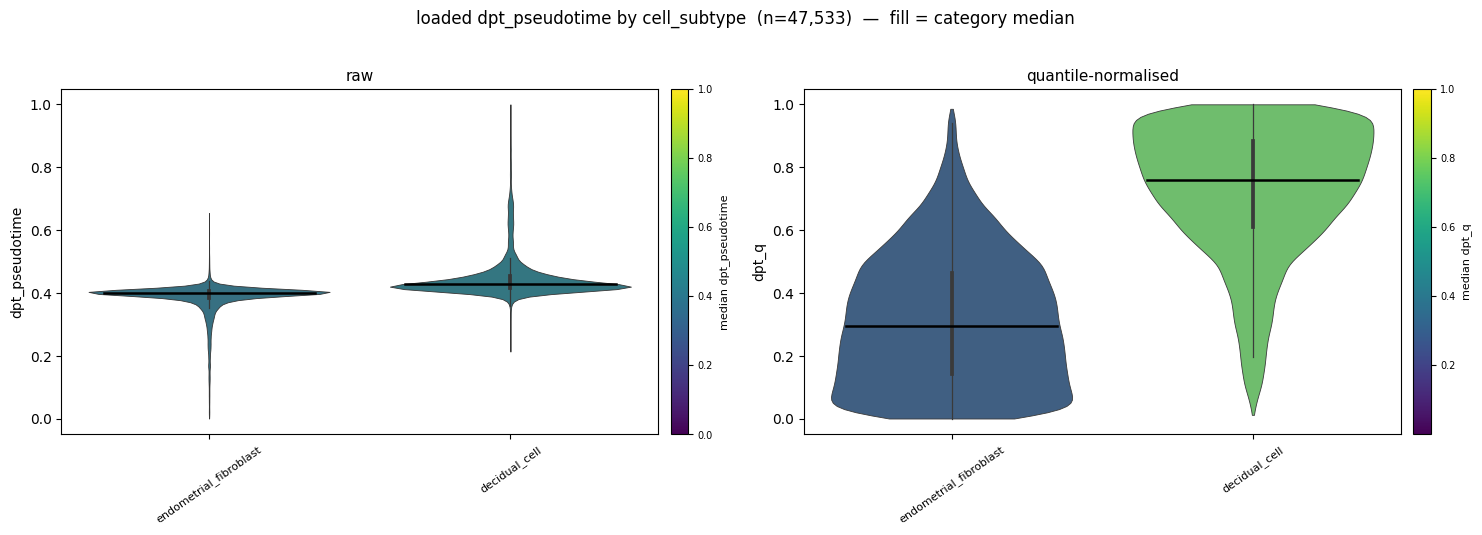

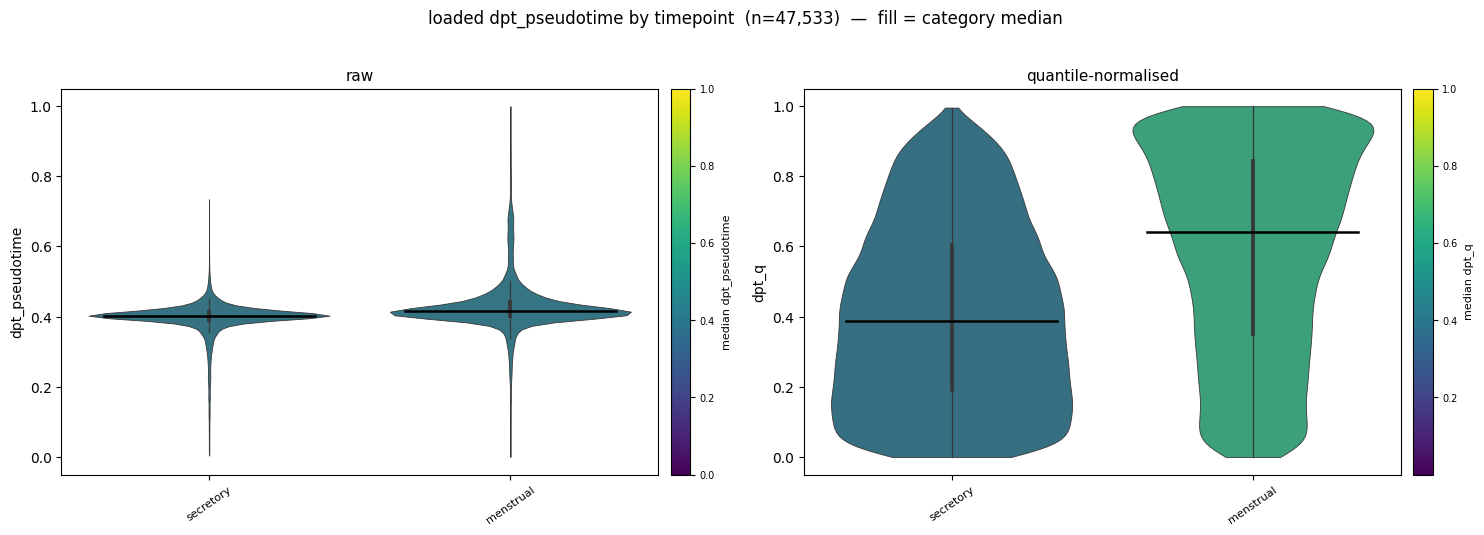

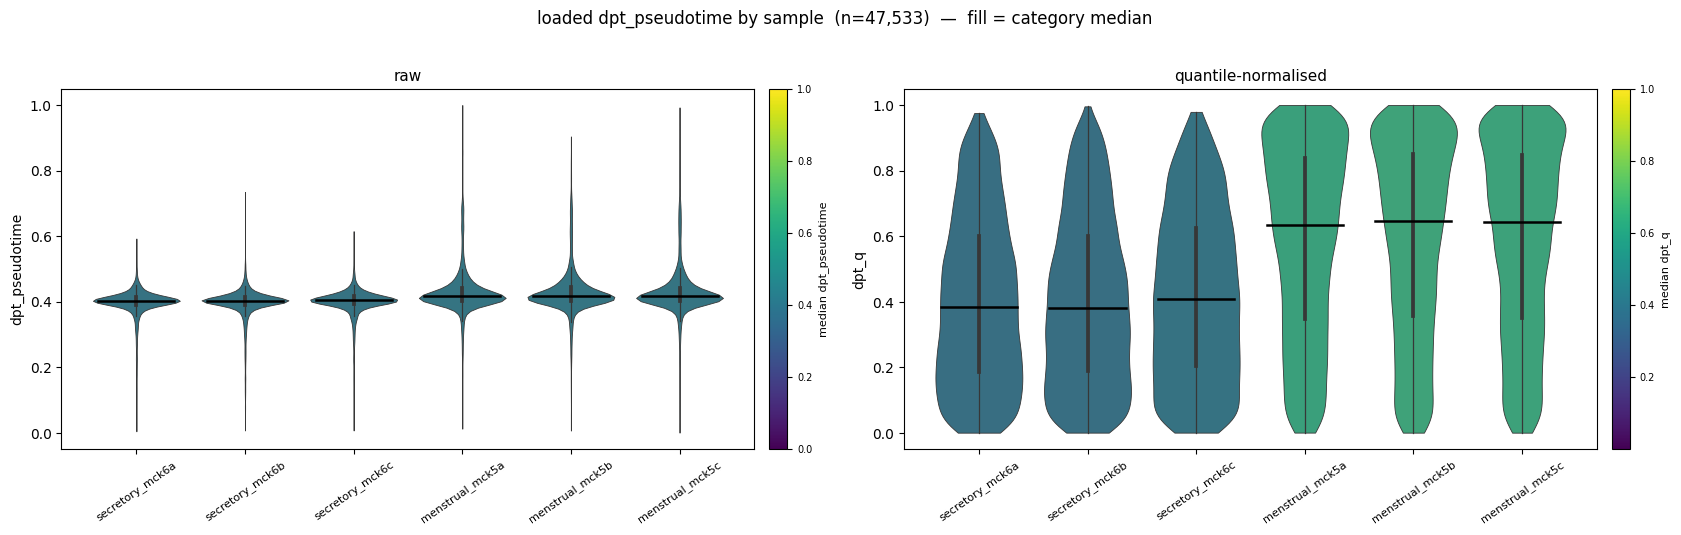

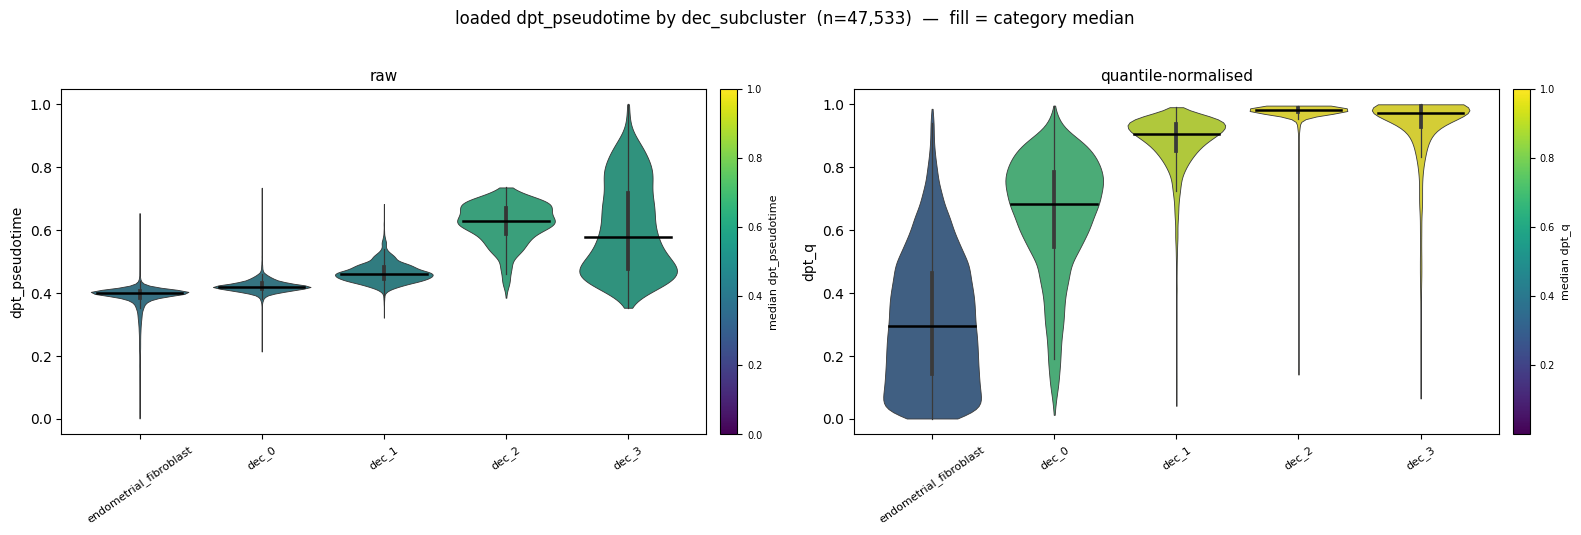

In [6]:
def violins(by, order=None, pal=None, cmap="viridis", vlim=None, figsize=(15, 5.2)):
    """Raw beside quantile-normalised. Fill colour = that category's MEDIAN of the column plotted, on the
    same colour scale the spatial panels use for that column (raw = data range, quantile = 0-1), so a
    violin's colour is the colour the tissue takes at that category's typical position. The two panels are
    coloured independently because their medians are on different scales. Black bar = median.
    vlim={column: (vmin, vmax)} forces the scale; pal={cat: colour} falls back to categorical colouring."""
    order = order or [s for s in (SUBORDER if by == "cell_subtype" else TPORDER) if s in set(res[by])]
    d = res[res[PTCOL].notna()]
    fig, axes = plt.subplots(1, 2, figsize=figsize, sharex=True)
    meds = {}
    for ax, col in zip(axes, (PTCOL, "dpt_q")):
        med = d.groupby(by, observed=True)[col].median().reindex(order); meds[col] = med
        if pal is None:
            lo, hi = (vlim or {}).get(col, (float(d[col].min()), float(d[col].max())))
            norm = Normalize(vmin=lo, vmax=hi)
            colours = {c_: plt.get_cmap(cmap)(norm(med[c_])) for c_ in order if pd.notna(med[c_])}
            sm = ScalarMappable(norm=norm, cmap=cmap)
        else:
            colours, sm = pal, None
        sns.violinplot(data=d, x=by, y=col, order=order, hue=by, hue_order=order,
                       palette=colours, legend=False, cut=0, linewidth=.6, ax=ax)
        for k, c_ in enumerate(order):
            if pd.notna(med.get(c_)): ax.plot([k-.35, k+.35], [med[c_]]*2, c="k", lw=1.8, zorder=5)
        ax.set_title("raw" if col == PTCOL else "quantile-normalised", fontsize=11)
        ax.set_xlabel(""); ax.tick_params(axis="x", rotation=35, labelsize=8)
        if sm is not None:
            cb = fig.colorbar(sm, ax=ax, fraction=.046, pad=.02)
            cb.set_label(f"median {col}", fontsize=8); cb.ax.tick_params(labelsize=7)
    fig.suptitle(f"loaded {PTCOL} by {by}  (n={len(d):,})  —  fill = category median", y=1.02)
    fig.tight_layout(); return fig, pd.DataFrame(meds).round(4)

fig, MED_SUB = violins("cell_subtype"); display(MED_SUB)
fig, MED_TP  = violins("timepoint");    display(MED_TP)
SAMPLE_ORDER = [s for t in TPORDER for s in sorted(res["sample"].unique()) if s.startswith(t)]
fig, MED_SMP = violins("sample", SAMPLE_ORDER, figsize=(17, 5.2)); display(MED_SMP)
if res.dec_subcluster.nunique() > 2:
    DORDER = ["endometrial_fibroblast"] + sorted(x for x in res.dec_subcluster.unique() if x.startswith("dec_"))
    fig, MED_DEC = violins("dec_subcluster", DORDER, figsize=(16, 5.2)); display(MED_DEC)

## 5 — spatial: raw, quantile (global), quantile (within section)

One row per tissue section, ordered by phase — six sections, one puck each. Raw and global-quantile share one colour scale across all sections; within-section is 0–1 by construction.

33,247 of 47,533 cells have both a pseudotime and a QC'd coordinate | 6 sections


tissue_section,secretory_mck6a__A,secretory_mck6b__A,secretory_mck6c__A,menstrual_mck5a__A,menstrual_mck5b__A,menstrual_mck5c__A
n_cells,7293,7131,4325,4863,5148,4487


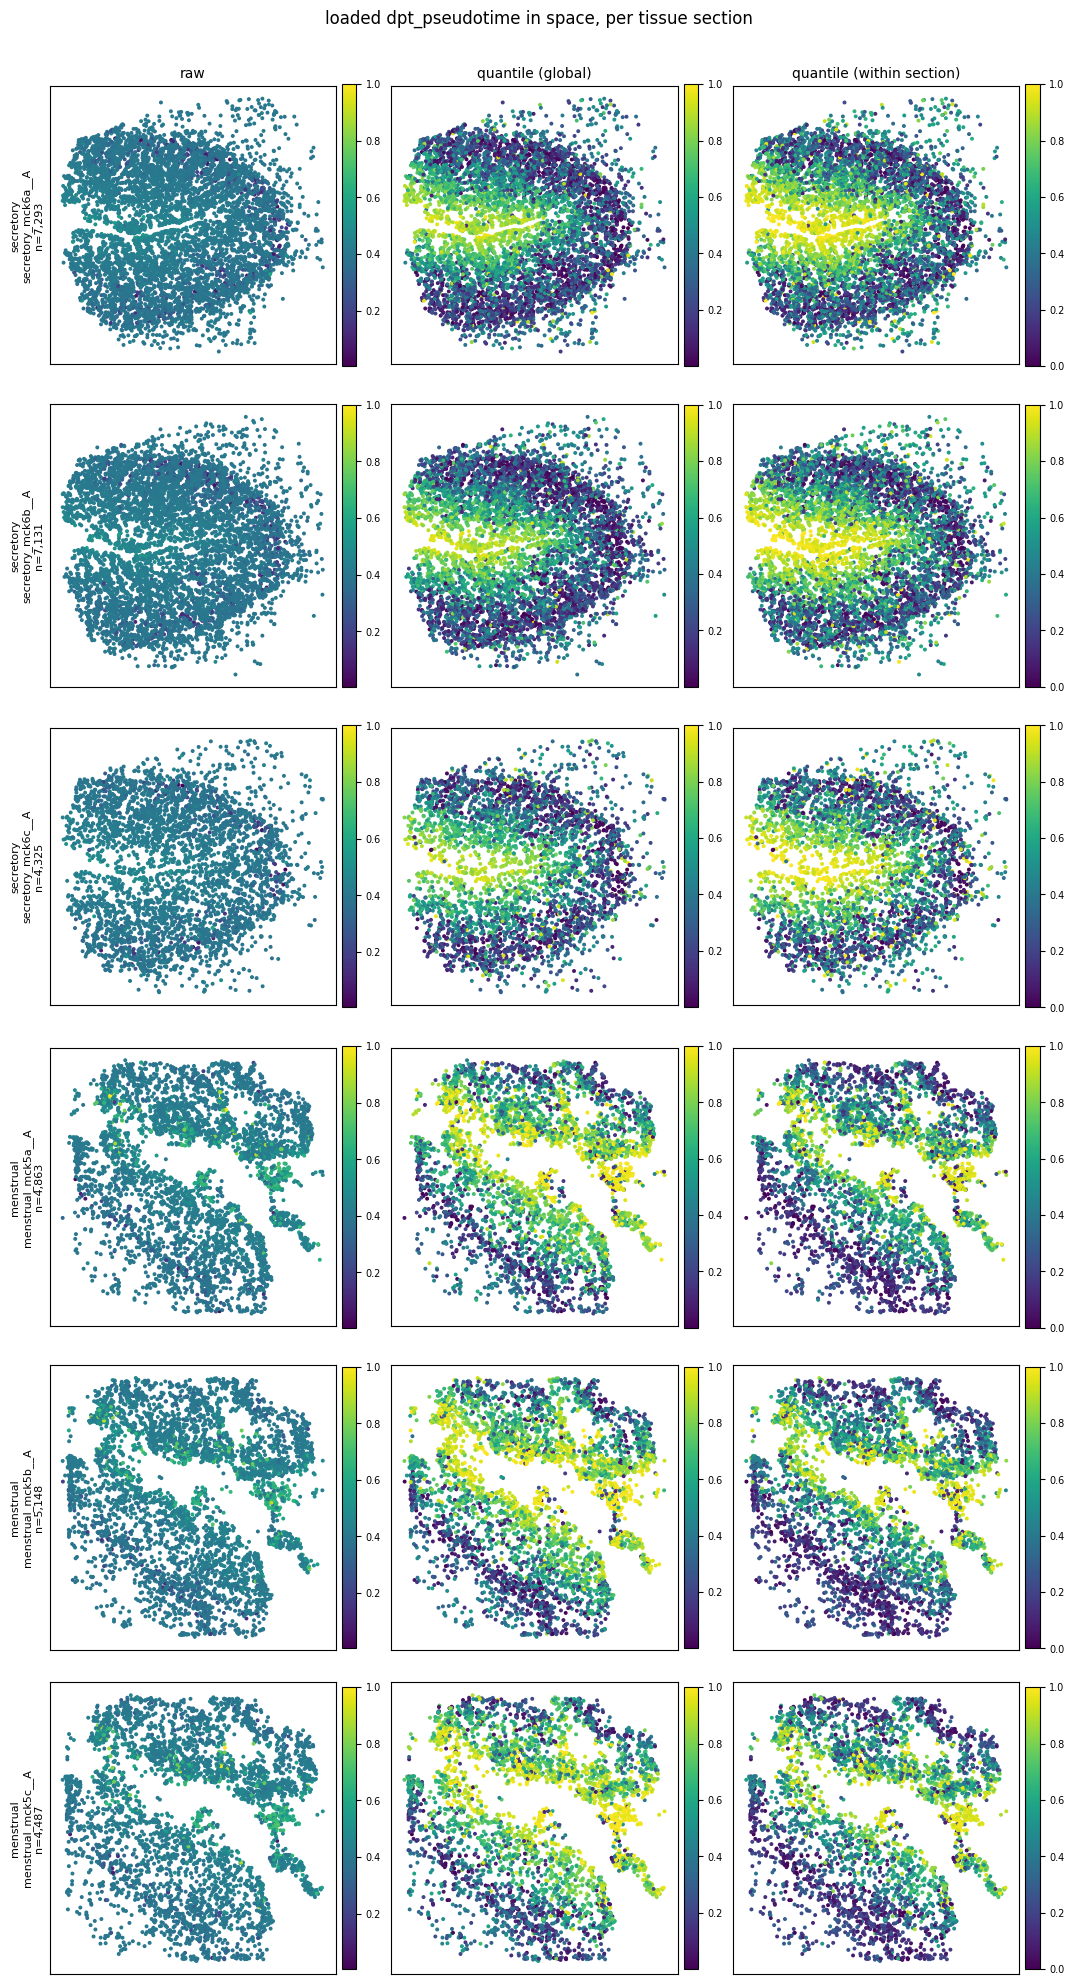

In [7]:
SP = res[res[PTCOL].notna() & np.isfinite(res.x_um_qc) & (res.tissue_section != "nan") & res.tissue_section.notna()].copy()
SEC2TP = SP.groupby("tissue_section", observed=True).timepoint.first().to_dict()
secs = sorted(SP.tissue_section.unique(), key=lambda s: (TPRANK.get(SEC2TP[s], 99), s))
SEC_BY_TP = {t: [s for s in secs if SEC2TP[s] == t] for t in TPORDER if any(SEC2TP[s] == t for s in secs)}
print(f"{len(SP):,} of {len(res):,} cells have both a pseudotime and a QC'd coordinate | {len(secs)} sections")
display(SP.groupby("tissue_section", observed=True).size().reindex(secs).rename("n_cells").to_frame().T)

COLS = (PTCOL, "dpt_q", "dpt_qsec"); LABS = {PTCOL:"raw", "dpt_q":"quantile (global)", "dpt_qsec":"quantile (within section)"}
def spatial_panels(per=3.6, s=3.4):
    fig, axes = plt.subplots(len(secs), len(COLS), figsize=(per*len(COLS), per*len(secs)*.92), squeeze=False)
    for i, sec in enumerate(secs):
        g = SP[SP.tissue_section == sec]
        for j, col in enumerate(COLS):
            ax = axes[i][j]; vmin, vmax = ((SP[col].min(), SP[col].max()) if col != "dpt_qsec" else (0, 1))
            sm = ax.scatter(g.x_um_qc, g.y_um_qc, c=g[col], s=s, cmap="viridis", vmin=vmin, vmax=vmax, rasterized=True)
            ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
            if i == 0: ax.set_title(LABS[col], fontsize=10)
            if j == 0: ax.set_ylabel(f"{SEC2TP[sec]}\n{sec}\nn={len(g):,}", fontsize=8)
            plt.colorbar(sm, ax=ax, fraction=.046, pad=.02).ax.tick_params(labelsize=7)
    fig.suptitle(f"loaded {PTCOL} in space, per tissue section", y=1.0); fig.tight_layout(); return fig
_ = spatial_panels()

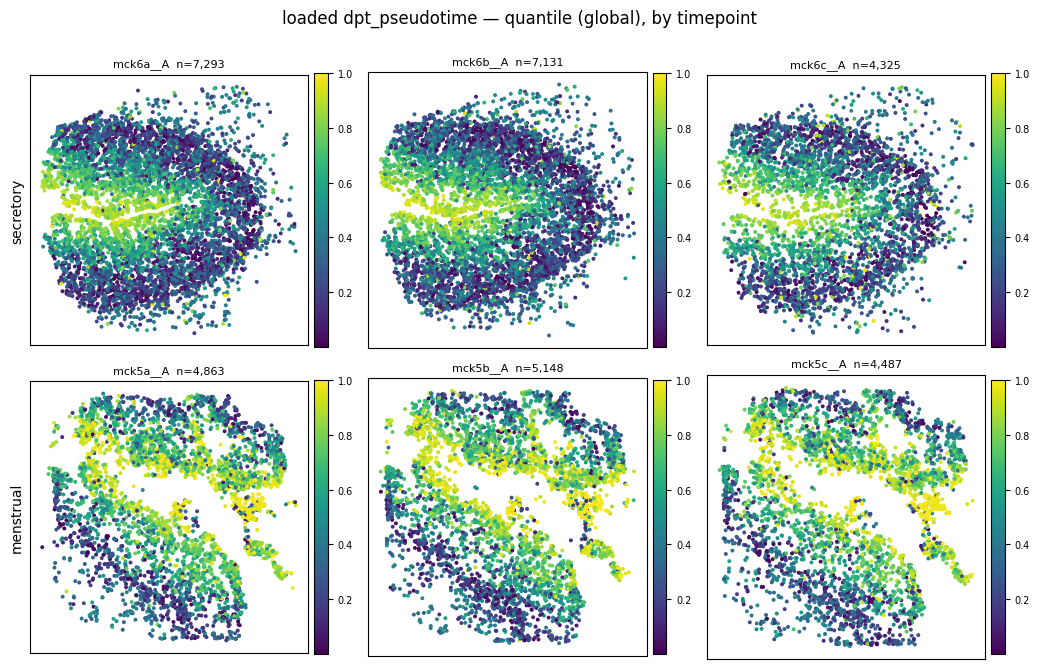

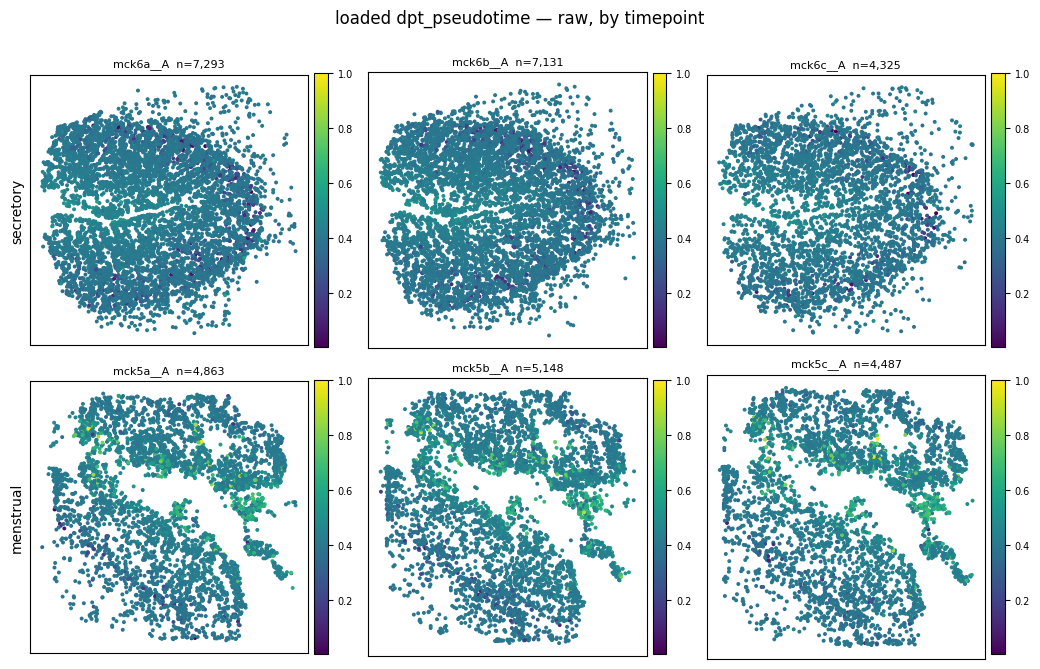

In [8]:
def spatial_by_timepoint(col="dpt_q", per=3.5, s=3.4):
    ncol = max(len(v) for v in SEC_BY_TP.values()); vmin, vmax = ((SP[col].min(), SP[col].max()) if col != "dpt_qsec" else (0, 1))
    fig, axes = plt.subplots(len(SEC_BY_TP), ncol, figsize=(per*ncol, per*len(SEC_BY_TP)*.95), squeeze=False)
    for i, (tp, sl) in enumerate(SEC_BY_TP.items()):
        for j in range(ncol):
            ax = axes[i][j]
            if j >= len(sl): ax.axis("off"); continue
            g = SP[SP.tissue_section == sl[j]]
            sm = ax.scatter(g.x_um_qc, g.y_um_qc, c=g[col], s=s, cmap="viridis", vmin=vmin, vmax=vmax, rasterized=True)
            ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{sl[j].replace(tp+'_','')}  n={len(g):,}", fontsize=8)
            if j == 0: ax.set_ylabel(tp, fontsize=10)
            plt.colorbar(sm, ax=ax, fraction=.046, pad=.02).ax.tick_params(labelsize=7)
    fig.suptitle(f"loaded {PTCOL} — {LABS[col]}, by timepoint", y=1.0); fig.tight_layout(); return fig
_ = spatial_by_timepoint("dpt_q"); _ = spatial_by_timepoint(PTCOL)

## 6 — save the table

In [ ]:
res.to_csv(OUT/"loaded_pseudotime_human.csv")
json.dump(dict(source=str(SRC), column=PTCOL, n_cells=int(len(res)), n_with_pt=int(res[PTCOL].notna().sum()),
               n_with_pt_and_coords=int(len(SP)), sections=len(secs), provenance=prov, uns=uns_pt,
               checks=[dict(label=l, ok=o, got=g) for l, o, g, _ in CHECKS]),
          open(OUT/"loaded_pseudotime_human_report.json", "w"), indent=1, default=str)
bad = [l for l, o, _, _ in CHECKS if not o]
print("wrote", OUT/"loaded_pseudotime_human.csv")
print(f"{len(CHECKS)} checks | {len(bad)} FAILED" + (": " + "; ".join(bad) if bad else " — all passed"))